# Plot Figure 5 posteriors of PFT parameters

In [1]:
import os, json, glob
import numpy as np
import xarray as xr
import pandas as pd
import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import Patch
import matplotlib as mpl
from scipy.stats import gaussian_kde
from matplotlib.colors import LinearSegmentedColormap

import warnings
warnings.filterwarnings("ignore")

In [2]:
# get config information
utils_dir = '../utils/'

with open(os.path.join(utils_dir, "param_info.json"), "r") as f:
    param_info = json.load(f)
universal_param_names = param_info['u_params']
pft_param_names = param_info['pft_params']

In [3]:
# Load NROY parameter sets 
in_file = '../data/wave4_NROY_samples.csv'
NROY_samples = pd.read_csv(in_file)

In [4]:
default_norm = pd.read_csv('../clm-hmc/default_params_norm.csv',index_col=0)

### Figure 5

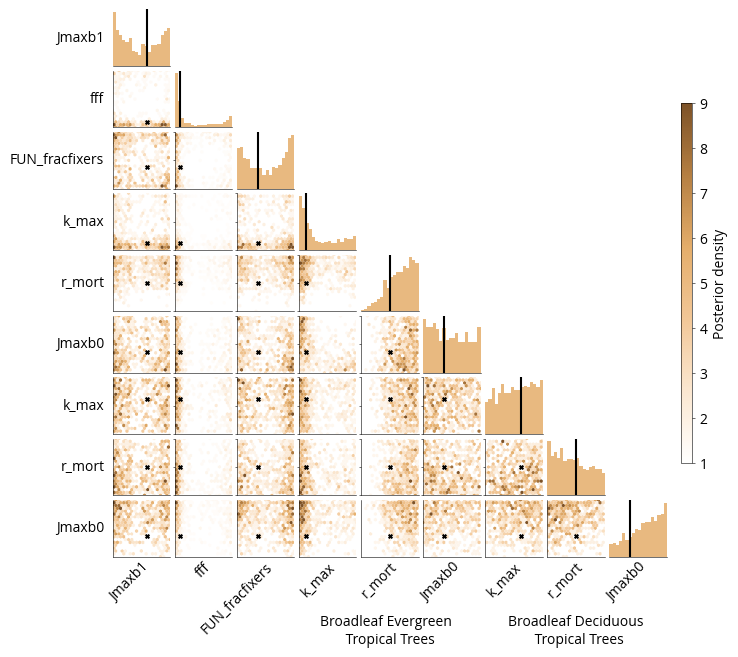

In [6]:
params = ['jmaxb1', 'fff', 'FUN_fracfixers',
          'pft4_kmax', 'pft4_r_mort','pft4_jmaxb0',
          'pft6_kmax', 'pft6_r_mort','pft6_jmaxb0', 
          ]
            
labels = {
    'jmaxb1': 'Jmaxb1',
    'fff': 'fff',               'FUN_fracfixers': 'FUN_fracfixers',
    'pft4_kmax': 'k_max',     'pft6_kmax': 'k_max',
    'pft4_r_mort': 'r_mort',  'pft6_r_mort': 'r_mort',
    'pft4_jmaxb0': 'Jmaxb0',  'pft6_jmaxb0': 'Jmaxb0',
    
}

groups = {'pft4': 'Broadleaf Evergreen \n Tropical Trees', 'pft6': 'Broadleaf Deciduous \n Tropical Trees'}

data = NROY_samples[params]
n = len(params)

# prior bounds 
lims = {p: (0, 1) for p in params}

sandstone = LinearSegmentedColormap.from_list('sandstone_ext', ['#FFFFFF', '#FBE7D0', '#F2C797', '#E4AD6A', '#B57F42', '#7D5227'])
cmap = sandstone  

last_hex = '#E4AD6A'

plt.rcParams.update({
    'font.family': 'sans-serif', 'font.sans-serif': ['Open Sans'],
    'font.size': 10, 'axes.labelsize': 10, 'axes.titlesize': 10,
    'xtick.labelsize': 6, 'ytick.labelsize': 6,
    'axes.linewidth': 0.4, 'xtick.major.width': 0.4, 'ytick.major.width': 0.4,
    'xtick.major.size': 1.8, 'ytick.major.size': 1.8,
    'pdf.fonttype': 42, 'ps.fonttype': 42,
})

fig, axes = plt.subplots(n, n, figsize=(7.2, 7.2), sharex='col')

for i in range(n):
    for j in range(n):
        ax = axes[i, j]

        if i == j:
            ax.hist(data[params[i]], bins=18, range=lims[params[i]],
                    color=last_hex, alpha=0.85, linewidth=0)
            ax.axvline(default_norm[params[j]][0],color='k')
            ax.set_yticks([])
            for s in ('top', 'right', 'left'):
                ax.spines[s].set_visible(False)

        elif i > j:
            hb = ax.hexbin(data[params[j]], data[params[i]], gridsize=18,
                      extent=(*lims[params[j]], *lims[params[i]]),
                      cmap=cmap, mincnt=1, linewidths=0, rasterized=True)
            ax.scatter(default_norm[params[j]],default_norm[params[i]],s=7,color='k',marker='x')
            ax.set_ylim(*lims[params[i]])
            for s in ('top', 'right'):
                ax.spines[s].set_visible(False)

        else:
            r = data[params[j]].corr(data[params[i]], method='spearman')
            #ax.set_facecolor(cmap(0.5 + r / 2) if abs(r) > 0.15 else 'none')
            #ax.text(0.5, 0.5, f'{r:.2f}', ha='center', va='center',
            #        fontsize=6, color='0.25' if abs(r) < 0.4 else 'white',
            #        transform=ax.transAxes)
            ax.set_xticks([]); ax.set_yticks([])
            for s in ax.spines.values():
                s.set_visible(False)

        
        ax.set_xlim(*lims[params[j]])

        if i == n - 1:
            ax.set_xlabel(labels[params[j]], labelpad=2,
                          rotation=45, ha='right', rotation_mode='anchor')
            ax.set_xticks([])
            ax.set_yticks([])
            ax.tick_params(bottom=False, left=False)
        else:
            ax.tick_params(labelbottom=False)

        if j == 0 :
            ax.set_ylabel(labels[params[i]], labelpad=6,
                          rotation=0, ha='right', va='center')
            ax.set_yticks([])
        elif i != j:
            ax.tick_params(labelleft=False)

for i in range(n):
    for j in range(n):
        if i < j:
            axes[i, j].set_xticks([])
            axes[i, j].set_yticks([])
            axes[i, j].tick_params(labelbottom=False, labelleft=False,
                                   bottom=False, left=False)

# PFT group labels
for pft, name in groups.items():
    idx = [k for k, p in enumerate(params) if p.startswith(pft + '_')]
    if idx:
        x0 = axes[n - 1, idx[0]].get_position().x0
        x1 = axes[n - 1, idx[-1]].get_position().x1
        fig.text((x0 + x1) / 2, 0.0, name, ha='center', fontsize=10)


fig.subplots_adjust(wspace=0.08, hspace=0.08, bottom=0.12, left=0.13, right=0.90)

cax = fig.add_axes([0.92, 0.25, 0.015, 0.5])   # [left, bottom, width, height]
cb = fig.colorbar(hb, cax=cax)
cb.set_label('Posterior density', fontsize=10, labelpad=4)
cb.ax.tick_params(labelsize=10, width=0.4, length=1.8)
cb.outline.set_linewidth(0.4)

fig.savefig('../figs/figure5_posteriors_tropicPFTs.png',dpi=400, bbox_inches='tight')

### Figures S9 - S11: Compare posteriors

In [8]:
colors = ['#E4AD6A','#025196']

In [11]:
# load wave4 posteriors
dir='../clm-hm/paramsets/'
wave4_sets = pd.read_csv(dir+'wave4_paramsets.csv',index_col=0)

In [10]:
# load HMC posteriors
output_dir = '../clm-hmc/hmc_results/'
hmc_sets = pd.read_csv(output_dir+'selected_posterior_subset.csv',index_col=0)

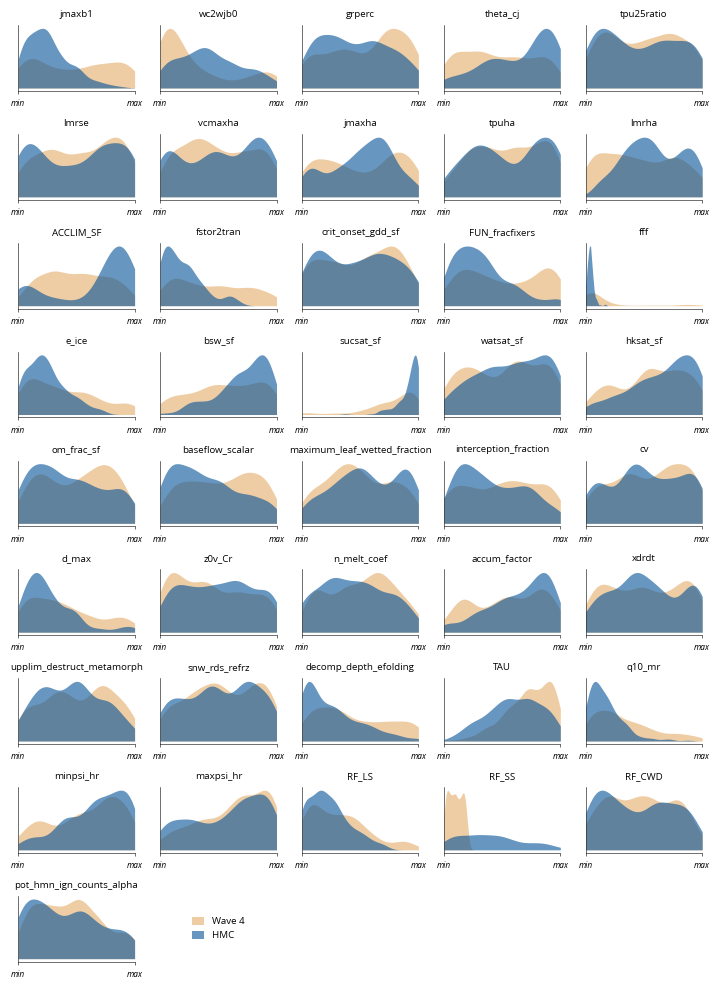

In [12]:
mpl.rcParams.update({
    'font.size': 7,
    'axes.linewidth': 0.4,
    'xtick.major.width': 0.4,
    'ytick.major.width': 0.4,
    'xtick.major.size': 2.5,
    'ytick.major.size': 2.5,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

data_w4 = wave4_sets.iloc[:, :41]
data_hmc = hmc_sets.iloc[:, :41]
n_params = data_w4.shape[1]

ncols = 5
nrows = int(np.ceil(n_params / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(7.2, nrows * 1.1))
axes_flat = axes.flatten()

for i in range(n_params):
    ax = axes_flat[i]
    x_w4 = data_w4.iloc[:, i].values
    x_hmc = data_hmc.iloc[:, i].values
    xmin = np.nanmin(np.concatenate([x_w4, x_hmc]))
    xmax = np.nanmax(np.concatenate([x_w4, x_hmc]))
    x_grid = np.linspace(xmin, xmax, 100)

    kde_w4 = gaussian_kde(x_w4, bw_method=0.3)
    kde_hmc = gaussian_kde(x_hmc, bw_method=0.3)

    ax.fill_between(x_grid, kde_w4(x_grid), color=colors[0], alpha=0.6, linewidth=0)
    ax.fill_between(x_grid, kde_hmc(x_grid), color=colors[1], alpha=0.6, linewidth=0)

    ax.set_title(data_w4.columns[i], fontsize=7)
    ax.set_yticks([])
    ax.set_xticks([xmin, xmax])
    ax.set_xticklabels(['min', 'max'], fontstyle='italic')
    ax.tick_params(axis='x', labelsize=6)
    ax.set_xlim(xmin, xmax)

# Hide unused panels
for j in range(n_params, len(axes_flat)):
    axes_flat[j].set_visible(False)

handles = [Patch(facecolor=colors[0], alpha=0.6, label='Wave 4'),
           Patch(facecolor=colors[1], alpha=0.6, label='HMC')]
if n_params < len(axes_flat):
    axes_flat[n_params].set_visible(True)
    axes_flat[n_params].axis('off')
    axes_flat[n_params].legend(handles=handles, frameon=False, fontsize=7,
                                loc='center', handlelength=1.2, handleheight=0.8)
else:
    fig.legend(handles=handles, frameon=False, fontsize=7,
               loc='upper right', bbox_to_anchor=(0.99, 0.99))

# add orange star for parameters where posterior is not different rom prior. 

fig.tight_layout()
fig.savefig('../figs/SI_FigS8_UniversalPosteriors_w4_hmc.png', dpi=300, bbox_inches='tight')

### Half violins

In [13]:
PFT_names = ['Other','NET Temperate','NET Boreal','NDT Boreal','BET Tropical','BET Temperate','BDT Tropical','BDT Temperate','BDT Boreal',
             'BES','BDS Temperate','BDS Boreal','C3G arctic','C3G non-arctic','C4G']

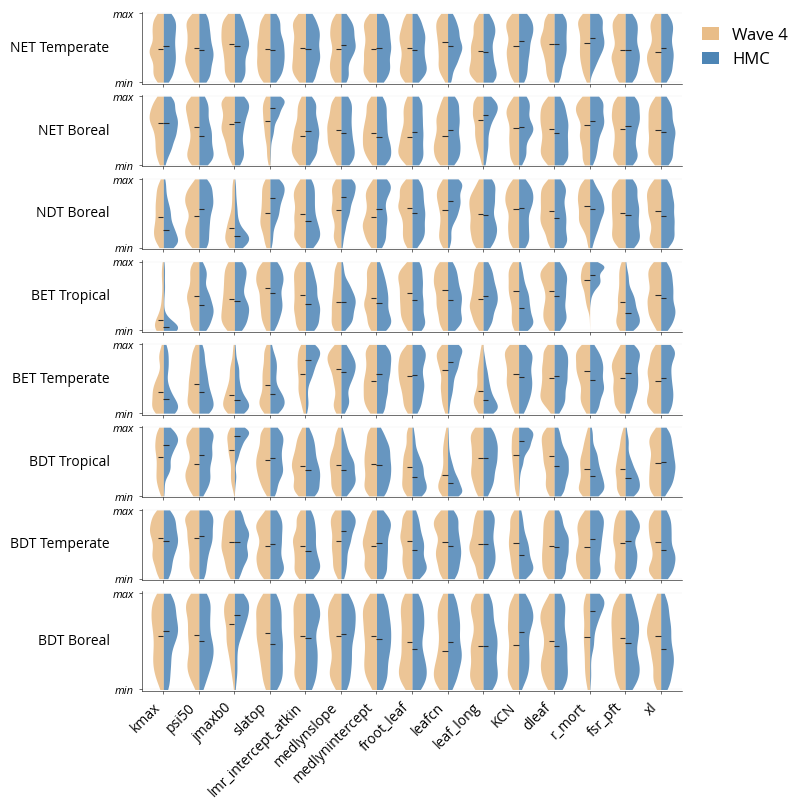

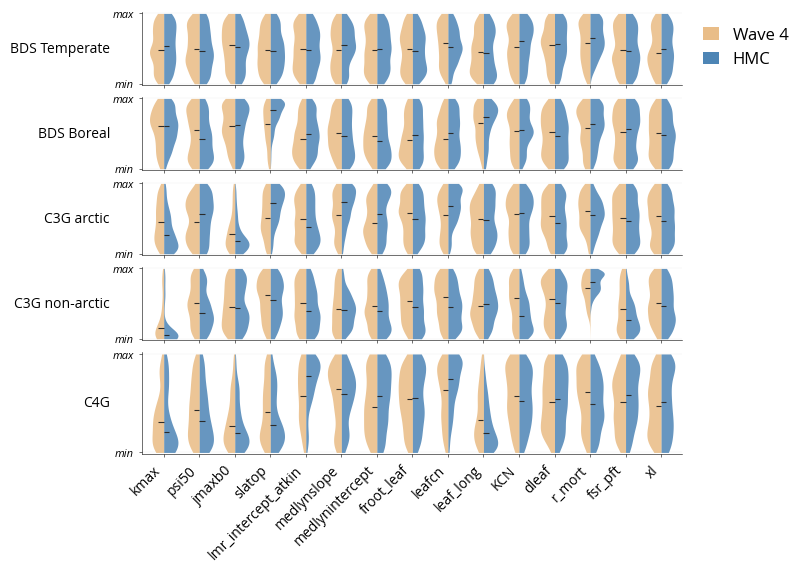

In [14]:
mpl.rcParams.update({
    'font.size': 7,
    'axes.linewidth': 0.4,
    'xtick.major.width': 0.4,
    'ytick.major.width': 0.4,
    'xtick.major.size': 2.5,
    'ytick.major.size': 2.5,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

pft_groups = [
    [1, 2, 3, 4, 5, 6, 7, 8],
    [10, 11, 12, 13, 14],
]

def plot_pft_panel(ax, pft, data_w4, data_hmc, show_xticks=False, show_legend=False):
    n_params = data_w4.shape[1]
    positions = np.arange(1, n_params + 1)
    y_grid = np.linspace(0, 1, 200)
    half_width = 0.4

    for i, pos in enumerate(positions):
        kde_w4 = gaussian_kde(data_w4.iloc[:, i].values)
        kde_hmc = gaussian_kde(data_hmc.iloc[:, i].values)
        d_w4 = kde_w4(y_grid)
        d_hmc = kde_hmc(y_grid)
    
        # Shared normalization — preserves relative area
        scale = half_width / max(d_w4.max(), d_hmc.max())
        d_w4 = d_w4 * scale
        d_hmc = d_hmc * scale
    
        ax.fill_betweenx(y_grid, pos - d_w4, pos, color=colors[0],
                         alpha=0.7, linewidth=0)
        ax.fill_betweenx(y_grid, pos, pos + d_hmc, color=colors[1],
                         alpha=0.6, linewidth=0)

        med_w4 = np.median(data_w4.iloc[:, i])
        med_hmc = np.median(data_hmc.iloc[:, i])
        ax.hlines(med_w4, pos - 0.15, pos, color='#2a2a2a', linewidth=0.8)
        ax.hlines(med_hmc, pos, pos + 0.15, color='#2a2a2a', linewidth=0.8)

    clean_labels = [c.split('_', 1)[1] for c in data_w4.columns]
    ax.set_xticks(positions)
    if show_xticks:
        ax.set_xticklabels(clean_labels, rotation=45, ha='right', fontsize=10)
    else:
        ax.set_xticklabels([])
    ax.set_ylim(-0.02, 1.02)
    ax.set_yticks([0, 1.0])
    ax.set_yticklabels(['min', 'max'],fontstyle='italic')
    ax.tick_params(axis='y', labelsize=8)
    ax.set_xlim(0.4, n_params + 0.6)
    ax.yaxis.grid(True, linestyle='-', linewidth=0.2, alpha=0.4, color='#bbbbbb')
    ax.set_axisbelow(True)

    # PFT label as a left-side annotation rather than a title — saves vertical space
    ax.text(-0.06, 0.5, PFT_names[pft], transform=ax.transAxes,
            fontsize=10, ha='right', va='center')

    if show_legend:
        ax.legend(handles=[Patch(facecolor=colors[0], alpha=0.8, label='Wave 4'),
                           Patch(facecolor=colors[1], alpha=0.7, label='HMC')],
                  frameon=False, fontsize=12, loc='upper left',
                  bbox_to_anchor=(1.01, 1.0), handlelength=1, handleheight=0.8)


for fig_idx, pft_list in enumerate(pft_groups):
    n_pfts = len(pft_list)
    # Bottom panel needs more height to fit rotated xtick labels
    height_ratios = [1] * (n_pfts - 1) + [1.4]
    fig, axes = plt.subplots(
        n_pfts, 1,
        figsize=(7.2, 1.0 * n_pfts + 0.6),
        sharex=True,
        gridspec_kw={'height_ratios': height_ratios, 'hspace': 0.15},
    )

    for row, pft in enumerate(pft_list):
        # Recompute the parameter slice for this PFT
        s = 41 + (row) * 15  # adjust if your indexing differs
        e = s + 15
        data_w4 = wave4_sets.iloc[:, s:e]
        data_hmc = hmc_sets.iloc[:, s:e]

        is_last = (row == n_pfts - 1)
        is_first = (row == 0)
        plot_pft_panel(axes[row], pft, data_w4, data_hmc,
                       show_xticks=is_last, show_legend=is_first)

    # Single shared y-label
    #fig.text(0.01, 0.5, 'Normalized parameter value',
    #         rotation=90, va='center', ha='center', fontsize=10)

    fig.subplots_adjust(left=0.13, right=0.88, top=0.97, bottom=0.18)
    fig.savefig(f'../figs/SI_FigureS10_PFTposteriors_group{fig_idx + 1}_w4_hmc.png',
                dpi=300, bbox_inches='tight')